# Retail Sales Analysis: Superstore Dataset

**Objective:** Identify which products, regions, and discount levels drive or hurt profit for a retail store, and turn the findings into business recommendations.

**Tools:** Python, Pandas, Matplotlib, Seaborn

**Dataset:** Superstore Sales Dataset (public sample data, available on Kaggle): 9,994 order lines with sales, profit, discount, category, region and customer details. All amounts are in US dollars.

**Business questions**
1. Which categories and sub-categories earn the most profit, and which lose money?
2. How do sales change over time (yearly growth and monthly seasonality)?
3. Which regions and states underperform?
4. How does discount level affect profit?
5. Who are the top customers by revenue, and are they profitable?

## 1. Setup and Data Loading

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

os.makedirs("images", exist_ok=True)

def save(name):
    plt.savefig(f"images/{name}.png", dpi=150, bbox_inches="tight")

In [2]:
df = pd.read_csv("data/superstore.csv", encoding="latin-1")
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 2. Data Understanding

A quick look at size, data types and summary statistics before changing anything.

In [3]:
print("Rows, columns:", df.shape)
df.info()

Rows, columns: (9994, 21)
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float6

In [4]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


**Key columns**
- `Sales`: revenue from the order line
- `Profit`: profit on that line (negative means the line lost money)
- `Discount`: discount applied, from 0 (none) to 1 (100%)
- `Quantity`: units sold on the line
- `Segment`, `Region`, `State`: customer type and location
- `Category` and `Sub-Category`: product hierarchy

## 3. Data Cleaning

Check for duplicates and missing values, fix data types, and create the extra columns used in the analysis.

In [5]:
print("Duplicate rows:", df.duplicated().sum())
print("Total missing values:", df.isnull().sum().sum())

Duplicate rows: 0
Total missing values: 0


In [6]:
df = df.drop_duplicates()

df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

df["Year"] = df["Order Date"].dt.year
df["Month Num"] = df["Order Date"].dt.month
df["Profit Margin %"] = df["Profit"] / df["Sales"] * 100
df["Delivery Days"] = (df["Ship Date"] - df["Order Date"]).dt.days

print("Clean shape:", df.shape)
df[["Order Date", "Year", "Profit Margin %", "Delivery Days"]].head()

Clean shape: (9994, 25)


,Order Date,Year,Profit Margin %,Delivery Days
0,2016-11-08,2016,16.00,3
1,2016-11-08,2016,30.00,3
2,2016-06-12,2016,47.00,4
3,2015-10-11,2015,-40.00,7
4,2015-10-11,2015,11.25,7


**What I checked and did**
- Duplicates: none found
- Missing values: none found
- Converted `Order Date` and `Ship Date` from text to datetime
- Created `Year`, `Month Num`, `Profit Margin %` and `Delivery Days` columns for the analysis

## 4. Overall Business Snapshot

In [7]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
print(f"Total sales:    ${total_sales:,.0f}")
print(f"Total profit:   ${total_profit:,.0f}")
print(f"Overall margin: {total_profit / total_sales * 100:.1f}%")
print(f"Orders:         {df['Order ID'].nunique():,}")

Total sales:    $2,297,201
Total profit:   $286,397
Overall margin: 12.5%
Orders:         5,009


## 5. Analysis

### Q1. Which categories and sub-categories make or lose money?

,Sales,Profit,Margin %
Category,,,
Technology,836154.0,145454.9,17.4
Office Supplies,719047.0,122490.8,17.0
Furniture,741999.8,18451.3,2.5


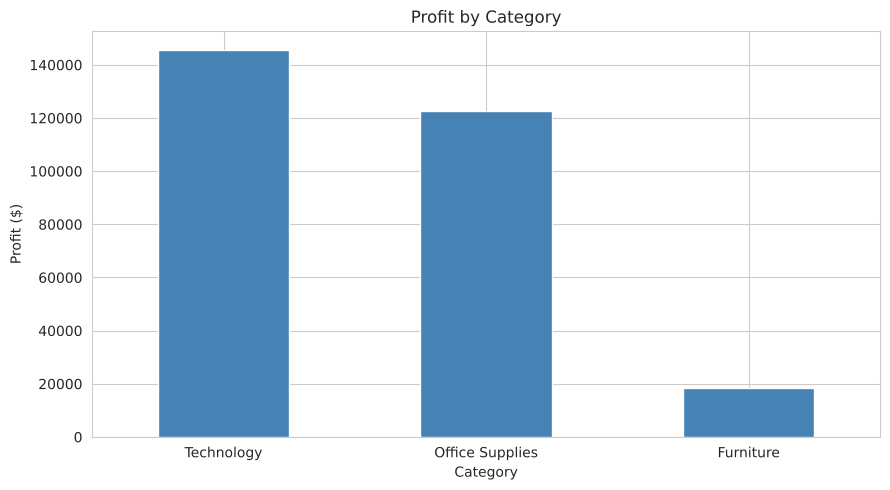

In [8]:
cat = df.groupby("Category")[["Sales", "Profit"]].sum().sort_values("Profit", ascending=False)
cat["Margin %"] = cat["Profit"] / cat["Sales"] * 100
display(cat.round(1))

cat["Profit"].plot(kind="bar", color="steelblue", title="Profit by Category")
plt.ylabel("Profit ($)")
plt.xticks(rotation=0)
plt.tight_layout()
save("01_profit_by_category")
plt.show()

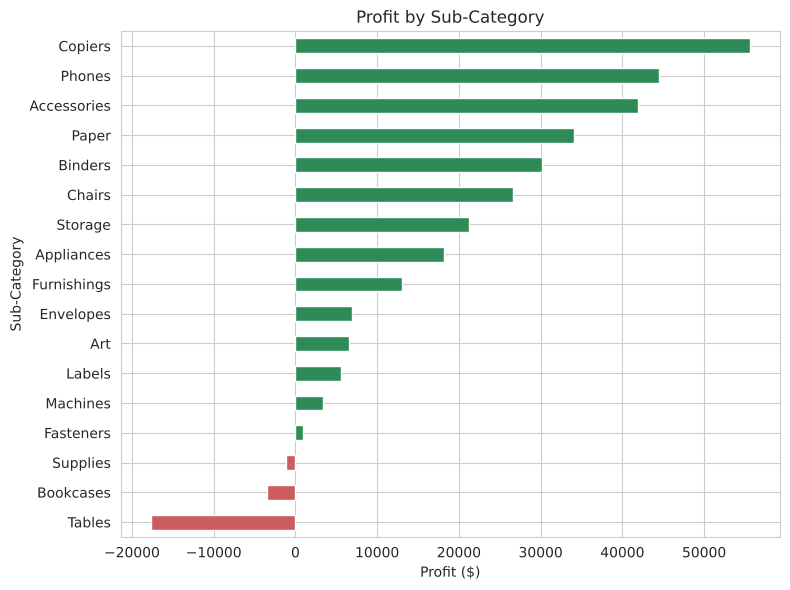

Loss-making sub-categories:
Sub-Category
Tables      -17725.0
Bookcases    -3473.0
Supplies     -1189.0
Name: Profit, dtype: float64


In [9]:
sub = df.groupby("Sub-Category")["Profit"].sum().sort_values()
colors = ["indianred" if v < 0 else "seagreen" for v in sub]

sub.plot(kind="barh", color=colors, figsize=(8, 6), title="Profit by Sub-Category")
plt.xlabel("Profit ($)")
plt.tight_layout()
save("02_profit_by_subcategory")
plt.show()

print("Loss-making sub-categories:")
print(sub[sub < 0].round(0))

> **Insight:** Technology ($145K profit) and Office Supplies ($122K) generate most of the profit. Furniture sells almost as much as the others ($742K) but earns only $18K, a 2.5% margin against about 17% elsewhere. Three sub-categories lose money: Tables (−$17.7K), Bookcases (−$3.5K) and Supplies (−$1.2K). Copiers ($55.6K), Phones ($44.5K) and Accessories ($41.9K) are the top earners.

### Q2. How do sales change over time?

,Sales,Profit,Sales Growth %
Year,,,
2014,484247.5,49544.0,NaN
2015,470532.5,61618.6,-2.8
2016,609205.6,81795.2,29.5
2017,733215.3,93439.3,20.4


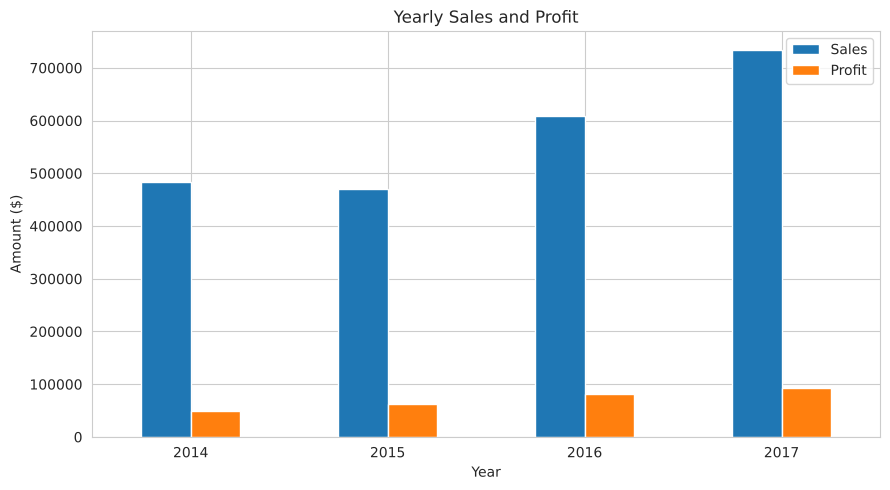

In [10]:
yearly = df.groupby("Year")[["Sales", "Profit"]].sum()
yearly["Sales Growth %"] = yearly["Sales"].pct_change() * 100
display(yearly.round(1))

yearly[["Sales", "Profit"]].plot(kind="bar", title="Yearly Sales and Profit")
plt.ylabel("Amount ($)")
plt.xticks(rotation=0)
plt.tight_layout()
save("03_yearly_sales_profit")
plt.show()

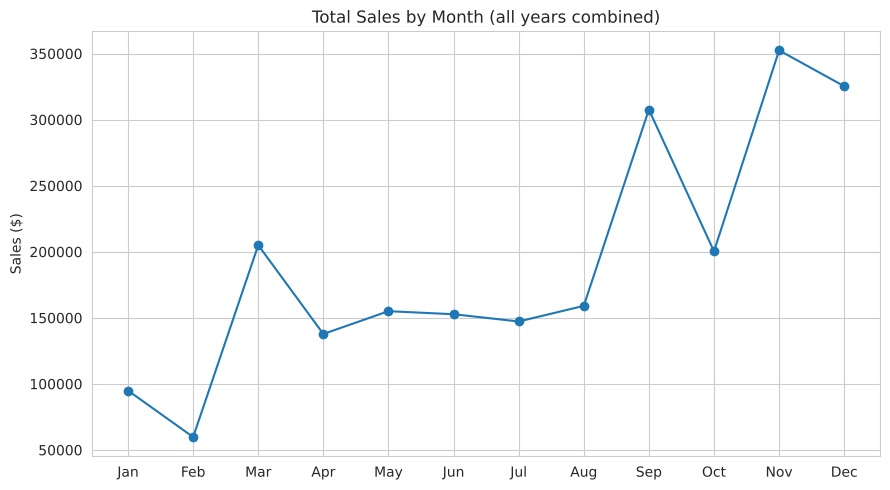

Nov + Dec share of total sales: 29.5%


In [11]:
monthly = df.groupby("Month Num")["Sales"].sum()
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.plot(month_labels, monthly.values, marker="o")
plt.title("Total Sales by Month (all years combined)")
plt.ylabel("Sales ($)")
plt.tight_layout()
save("04_monthly_seasonality")
plt.show()

print(f"Nov + Dec share of total sales: {(monthly[11] + monthly[12]) / monthly.sum() * 100:.1f}%")

> **Insight:** Sales dipped 2.8% in 2015, then grew 29.5% in 2016 and 20.4% in 2017, and profit rose every year (from $49.5K in 2014 to $93.4K in 2017). Sales are strongly seasonal: September, November and December are the peak months, with November and December alone making up nearly 30% of all sales. January and February are the weakest.

### Q3. Which regions and states underperform?

,Sales,Profit,Margin %
Region,,,
West,725457.8,108418.4,14.9
East,678781.2,91522.8,13.5
South,391721.9,46749.4,11.9
Central,501239.9,39706.4,7.9


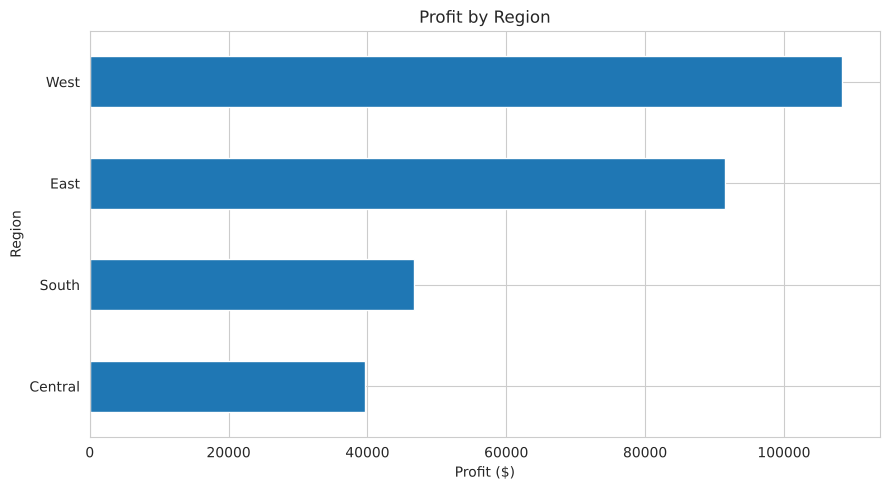

In [12]:
region = df.groupby("Region")[["Sales", "Profit"]].sum()
region["Margin %"] = region["Profit"] / region["Sales"] * 100
display(region.sort_values("Profit", ascending=False).round(1))

region["Profit"].sort_values().plot(kind="barh", title="Profit by Region")
plt.xlabel("Profit ($)")
plt.tight_layout()
save("05_profit_by_region")
plt.show()

In [13]:
state = df.groupby("State").agg(Profit=("Profit", "sum"), Avg_Discount=("Discount", "mean")).sort_values("Profit")
state["Avg_Discount"] = state["Avg_Discount"] * 100

print(f"Company-wide average discount: {df['Discount'].mean() * 100:.1f}%")
print()
print("Bottom 5 states by profit:")
display(state.head(5).round(1))
print("Top 5 states by profit:")
display(state.tail(5).round(1))

Company-wide average discount: 15.6%

Bottom 5 states by profit:


,Profit,Avg_Discount
State,,
Texas,-25729.4,37.0
Ohio,-16971.4,32.5
Pennsylvania,-15560.0,32.9
Illinois,-12607.9,39.0
North Carolina,-7490.9,28.4


Top 5 states by profit:


,Profit,Avg_Discount
State,,
Virginia,18598.0,0.0
Michigan,24463.2,0.7
Washington,33402.7,6.4
New York,74038.5,5.5
California,76381.4,7.3


> **Insight:** West (14.9% margin, $108K profit) and East (13.5%) lead, while Central is the weakest at a 7.9% margin despite $501K in sales. Four states lose heavily: Texas (−$25.7K), Ohio (−$17.0K), Pennsylvania (−$15.6K) and Illinois (−$12.6K), about −$71K combined. They also give much deeper discounts (32–39% on average) than California (7.3%) and New York (5.5%), the two most profitable states.

### Q4. How does discount level affect profit?

,Order_Lines,Avg_Profit,Total_Profit
Discount Band,,,
None,4798,66.9,320987.6
Low (up to 20%),3803,26.5,100785.5
Medium (20-40%),460,-77.9,-35817.5
High (40%+),933,-106.7,-99558.6


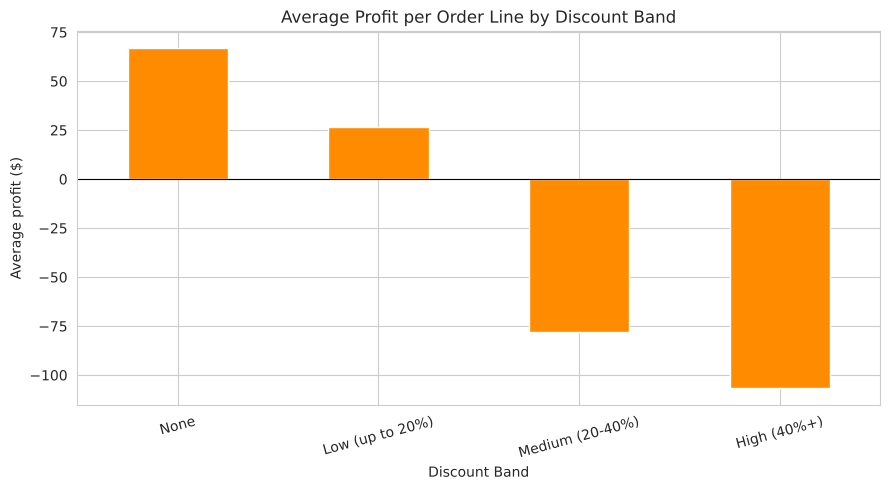

In [14]:
df["Discount Band"] = pd.cut(
    df["Discount"],
    bins=[-0.01, 0, 0.2, 0.4, 1.0],
    labels=["None", "Low (up to 20%)", "Medium (20-40%)", "High (40%+)"],
)

disc = df.groupby("Discount Band", observed=True).agg(
    Order_Lines=("Profit", "size"),
    Avg_Profit=("Profit", "mean"),
    Total_Profit=("Profit", "sum"),
)
display(disc.round(1))

disc["Avg_Profit"].plot(kind="bar", color="darkorange", title="Average Profit per Order Line by Discount Band")
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Average profit ($)")
plt.xticks(rotation=15)
plt.tight_layout()
save("06_discount_vs_avg_profit")
plt.show()

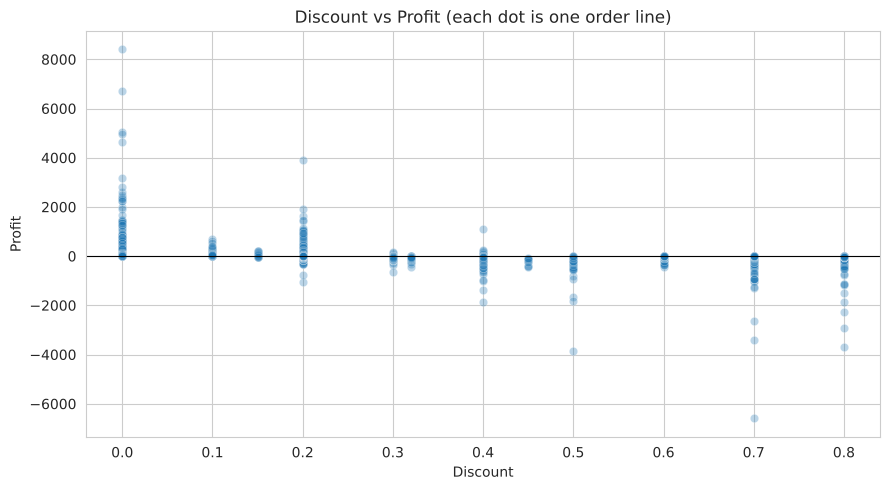

In [15]:
sns.scatterplot(data=df, x="Discount", y="Profit", alpha=0.3)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Discount vs Profit (each dot is one order line)")
plt.tight_layout()
save("07_discount_vs_profit_scatter")
plt.show()

In [16]:
loss = df[df["Profit"] < 0]
print(f"Loss-making order lines: {len(loss):,} of {len(df):,} ({len(loss) / len(df) * 100:.1f}%)")
print(f"Total loss on those lines: ${loss['Profit'].sum():,.0f}")
print(f"Share of loss-making lines with a discount of 30%+: {(loss['Discount'] >= 0.3).mean() * 100:.1f}%")

tables = df[df["Sub-Category"] == "Tables"]
print()
print("Tables profit when discount is 20% or more:", round(tables.loc[tables["Discount"] >= 0.2, "Profit"].sum()))
print("Tables profit when discount is under 20%:  ", round(tables.loc[tables["Discount"] < 0.2, "Profit"].sum()))

Loss-making order lines: 1,871 of 9,994 (18.7%)
Total loss on those lines: $-156,131
Share of loss-making lines with a discount of 30%+: 72.0%

Tables profit when discount is 20% or more: -31002
Tables profit when discount is under 20%:   13276


> **Insight:** Discounting is the biggest profit leak. Order lines with no discount average +$67 profit and those up to 20% still average +$27, but profit turns negative above 20%: −$78 per line at 20–40% and −$107 above 40%. Together those two bands lost about $135K. About 72% of all loss-making lines carry a discount of 30% or more. Tables show the same pattern: −$31K on lines discounted 20% or more, +$13K on the rest.

### Q5. Who are the top customers, and are they profitable?

,Sales,Profit
Customer Name,,
Sean Miller,25043.0,-1981.0
Tamara Chand,19052.0,8981.0
Raymond Buch,15117.0,6976.0
Tom Ashbrook,14596.0,4704.0
Adrian Barton,14474.0,5445.0
Ken Lonsdale,14175.0,807.0
Sanjit Chand,14142.0,5757.0
Hunter Lopez,12873.0,5622.0
Sanjit Engle,12209.0,2651.0


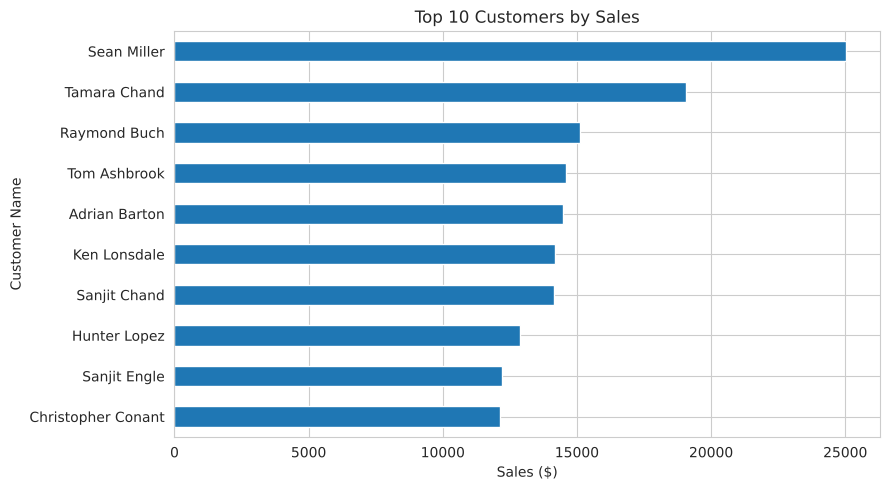

In [17]:
top = df.groupby("Customer Name")[["Sales", "Profit"]].sum().nlargest(10, "Sales")
display(top.round(0))

top["Sales"].sort_values().plot(kind="barh", title="Top 10 Customers by Sales")
plt.xlabel("Sales ($)")
plt.tight_layout()
save("08_top_customers")
plt.show()

In [18]:
seg = df.groupby("Segment")[["Sales", "Profit"]].sum()
seg["Margin %"] = seg["Profit"] / seg["Sales"] * 100
seg.round(1)

,Sales,Profit,Margin %
Segment,,,
Consumer,1161401.3,134119.2,11.5
Corporate,706146.4,91979.1,13.0
Home Office,429653.1,60298.7,14.0


> **Insight:** Revenue and profit don't always go together. The top customer by sales, Sean Miller ($25.0K), has a net loss of about $2.0K, while Tamara Chand ($19.1K sales) brings the most profit of the top 10 ($9.0K). Consumer is the largest segment ($1.16M sales, 11.5% margin), but Home Office (14.0%) and Corporate (13.0%) are more profitable per dollar of sales.

## 6. Key Insights

1. **Discounts above 20% destroy profit.** Lines discounted 20–40% average −$78 and 40%+ average −$107, against +$67 with no discount.
2. **Furniture is the weak category.** It sells as much as the others but earns a 2.5% margin (vs. about 17%), driven by losses in Tables and Bookcases.
3. **Four states lose about $71K combined** (Texas, Ohio, Pennsylvania, Illinois) and all four use heavy discounts of 32–39% on average.
4. **The business is growing and seasonal.** Sales grew 29.5% in 2016 and 20.4% in 2017, with September, November and December as the peak months.
5. **Big customers are not always profitable.** The top customer by sales has a net loss.

## 7. Recommendations

1. **Cap discounts at 20%** and require review for anything above it, starting with Furniture. This addresses insight 1.
2. **Reprice or stop discounting Tables** and review Bookcases, since both lose money. This addresses insight 2.
3. **Review the discount policy in Texas, Ohio, Pennsylvania and Illinois**, where heavy discounting goes with large losses. This addresses insight 3.
4. **Stock up and plan promotions around September to December**, and consider campaigns to lift the slow January and February months. This addresses insight 4.
5. **Track customer profit, not just revenue**, and review the terms of high-sales customers who are unprofitable. This addresses insight 5.

## 8. Conclusion and Next Steps

Profit in this dataset is held back mainly by heavy discounting, concentrated in Furniture (especially Tables) and four states, rather than by weak demand. Capping discounts is the clearest lever for improving margin.

**Limitations:** this is a sample dataset covering 2014–2017, so the analysis shows association, not proof that discounts cause the losses. A product could be discounted because it was already underperforming.

**Next steps:** run the same questions in SQL (see the `sql/` folder), build a Power BI or Tableau dashboard, and forecast monthly sales.